![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | EDA and Baseline

*Project 2 — Machine Learning: From Data to Predictions*

**Student:** Gabriel Gomes

**Dataset:** WikiArt 

---
## Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%reload_ext autoreload
%autoreload 2

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from pathlib import Path
from imagededup.methods import PHash


---
## 1. Frame the problem

**The question:** Given an image of a painting, which of six painters made it: Monet, Renoir, Morisot, Manet, Cézanne, Van Gogh? The prediction is aimed at art students, museum visitors, and cataloguers of digital collections, who could use it as a first-pass attribution: label an unlabeled image, suggest a likely artist, or flag a mislabeled catalog entry for an expert to check. It's an assistive tool, not a replacement for art historians, so a wrong label would be corrected by review, not acted on blindly.

**The target:** The painter's name, a categorical variable with 6 classes. Since this is multi-class classification, there is no single positive class. Each painter is treated as the positive class in turn (one-vs-rest) when computing per-class precision, recall, and F1. For a binary demo such as "Monet vs. not Monet", Monet would be the positive class.

**The metric:** **Macro-averaged F1** is the main metric.
- **Why macro-F1:** The classes will probably be imbalanced (WikiArt has far more images for some painters than others), and plain accuracy would reward a model that favors the big classes. Macro-F1 weighs every painter equally.
- **Per-class recall and a confusion matrix:** to see which painters get mixed up. I expect confusion between Monet and Renoir (the closest in technique), and between Renoir and Morisot (loose brushwork, similar soft palettes and figure subjects). Manet may be hard because his style varies widely, from flat early work to near-Impressionist outdoor scenes.
- **Top-2 accuracy:** a secondary measure, since a prediction where the correct artist is among the top two is still useful for suggesting candidates. With only six classes, top-3 would be too lenient.
- **Accuracy:** reported for reference only.

**Which mistake costs more:** No error is dangerous, but they differ in how meaningful they are. Confusing stylistic neighbors (Monet vs. Renoir) is understandable, even for human experts. Confusing painters with very different styles (Van Gogh vs. Morisot) suggests the model is relying on something other than style, such as subject, color, or image quality. For a catalog-assistance tool, **a confident wrong attribution is worse than an uncertain one**, because it can mislead the user. So I would also look at the model's confidence on its errors and consider showing the top-2 predictions with probabilities instead of a single label. Since no painter's misclassification is more costly than another's, I'm not weighting the metric toward precision or recall for any particular class.

---
## 2. Load the raw data

In [2]:
df = build_dataframe(RAW)

---
## 3. First look

Shape: 5,770 rows × 3 columns, with no missing values.

Column types: All three columns are text.

- `path`:	File location of the painting image, the model’s input
- `artist`:	Painter’s name, the target
- `title`:	Painting title, metadata only

One row is one painting image: where the file is stored (path), who painted it (artist), and what it is called (title).

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5770 entries, 0 to 5769
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   path    5770 non-null   object
 1   artist  5770 non-null   str   
 2   title   5770 non-null   str   
dtypes: object(1), str(2)
memory usage: 331.1+ KB


In [4]:
df.head(10)

,path,artist,title
0,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,entrance-to-the-port-of-honfleur
1,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,farm-near-honfleur
2,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,poplars-on-the-banks-of-the-epte-autumn-1891
3,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,valley-of-the-creuse-afternoon-sunlight
4,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,the-landing-state
5,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,girls-in-the-garden
6,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,sun-setting-over-the-seine-at-lavacourt-winter...
7,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,dolceacqua-bridge
8,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,poplars-view-from-the-marsh-1892
9,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Monet,grainstacks-white-frost-effect-1891


---
## 4. The target

**Target**: artist, a categorical variable with 6 classes and 5,770 images.

| Artist   | Images | Share |
|----------|-------:|------:|
| Van Gogh |  1,929 | 33.4% |
| Renoir   |  1,412 | 24.5% |
| Monet    |  1,365 | 23.7% |
| Cézanne  |    587 | 10.2% |
| Morisot  |    242 |  4.2% |
| Manet    |    235 |  4.1% |


**The imbalance is moderate to strong.** The largest class (Van Gogh) is about 8 times the size of the smallest (Manet). Three painters make up 81.6% of the data, and Morisot and Manet together make up only 8.3%.

**Why accuracy would be misleading**:

A model that always predicts Van Gogh scores 33.4% accuracy without learning anything. This is the baseline to beat.
A model that handles Van Gogh, Renoir, and Monet well but ignores Cézanne, Morisot, and Manet entirely could still reach about 82% accuracy. Its macro-F1 would be at most about 0.5, because three of six classes score zero.
So high accuracy could hide a model that fails on exactly the painters who are hardest and most interesting (Manet, Morisot).

In [5]:
df['artist'].value_counts()

artist
Van Gogh    1929
Renoir      1412
Monet       1365
Cézanne     587
Morisot      242
Manet        235
Name: count, dtype: int64

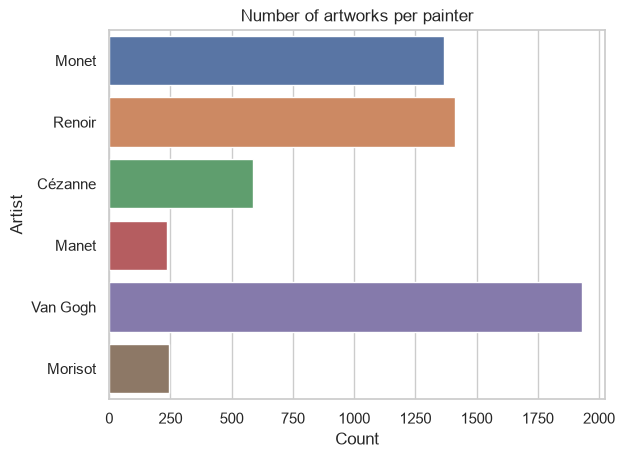

In [6]:
ax = sns.countplot(data=df, y='artist', hue='artist')
ax.set(
    title='Number of artworks per painter',
    xlabel='Count',
    ylabel='Artist'
)

plt.show()

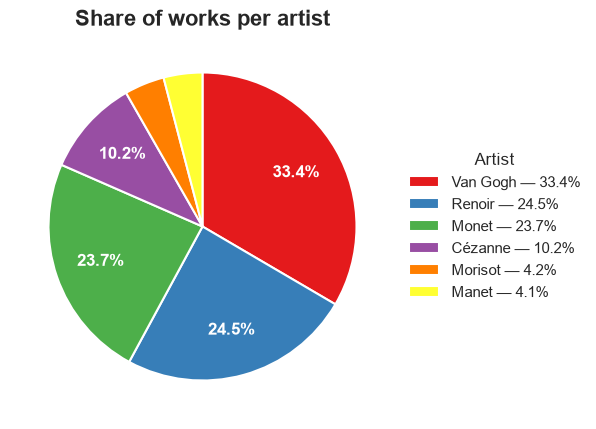

In [7]:
artist_freq = df['artist'].value_counts()

artist_proportions = df['artist'].value_counts(normalize=True)

norm_artist_proportions = artist_proportions / artist_proportions.sum()

fig, ax = plt.subplots(figsize=(7, 5))

counts = artist_freq.to_numpy()

wedges, _, _ = ax.pie(
    counts,
    startangle=90,
    counterclock=False,
    colors=sns.color_palette('Set1', n_colors=len(counts)),
    autopct=lambda p: f'{p:.1f}%' if p >= 5 else '',  # skip the slices too thin to hold text
    pctdistance=0.7,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    textprops={'color': 'white', 'fontsize': 12, 'fontweight': 'bold'},
)

ax.legend(
    wedges,
    [f'{label} — {p:.1%}' for label, p in norm_artist_proportions.items()],
    title='Artist',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    frameon=False,
)

ax.set_title('Share of works per artist', fontsize=16, fontweight='bold')
plt.show()

---
## 5. Range of image sizes

In [8]:
df = add_image_sizes(df)

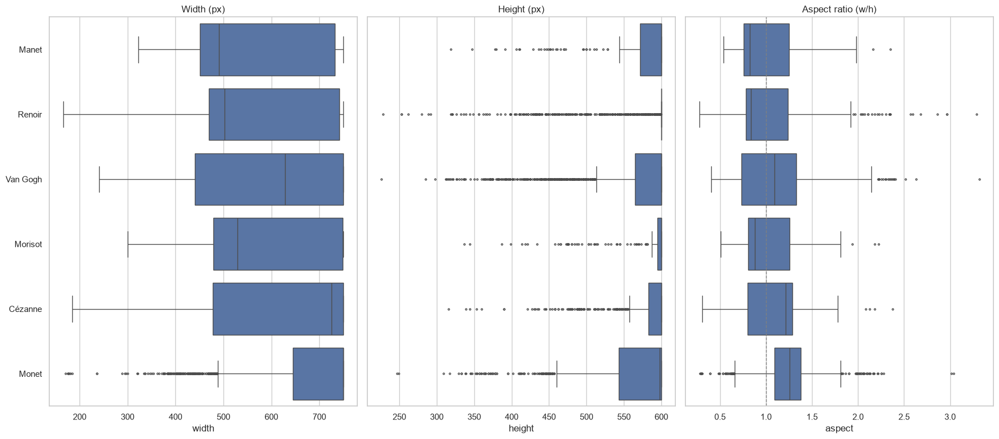

In [9]:
def plot_size_ranges(df, top_n=15):
    top = df["artist"].value_counts().head(top_n).index
    d = df[df["artist"].isin(top)]
    order = d.groupby("artist")["megapixels"].median().sort_values().index

    fig, axes = plt.subplots(1, 3, figsize=(18, 0.4 * top_n + 2), sharey=True)
    for ax, col, title in zip(
        axes,
        ["width", "height", "aspect"],
        ["Width (px)", "Height (px)", "Aspect ratio (w/h)"],
    ):
        sns.boxplot(data=d, y="artist", x=col, order=order, ax=ax, fliersize=2)
        ax.set_title(title)
        ax.set_ylabel("")
    axes[2].axvline(1, color="grey", linestyle="--", linewidth=1)   # square images
    plt.tight_layout()
    plt.show()

plot_size_ranges(df, top_n=15)

---
## 6. Example artworks per painter

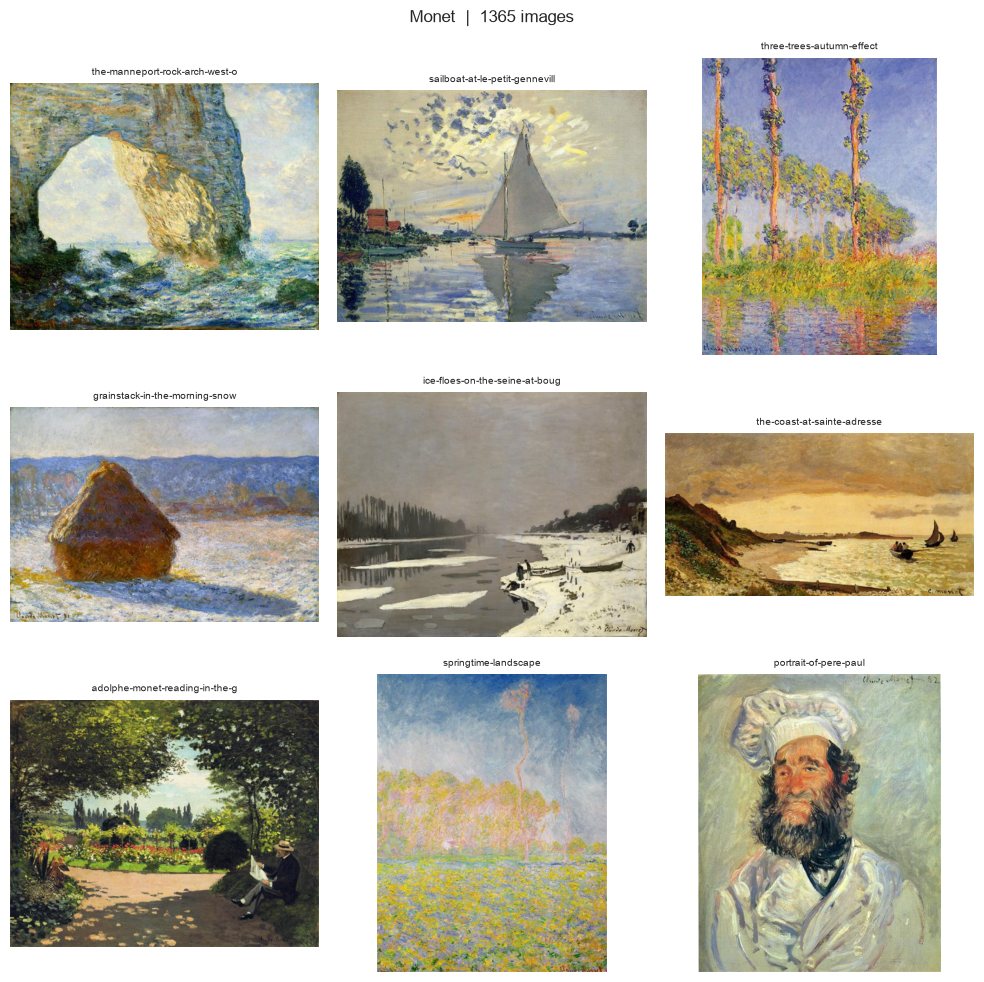

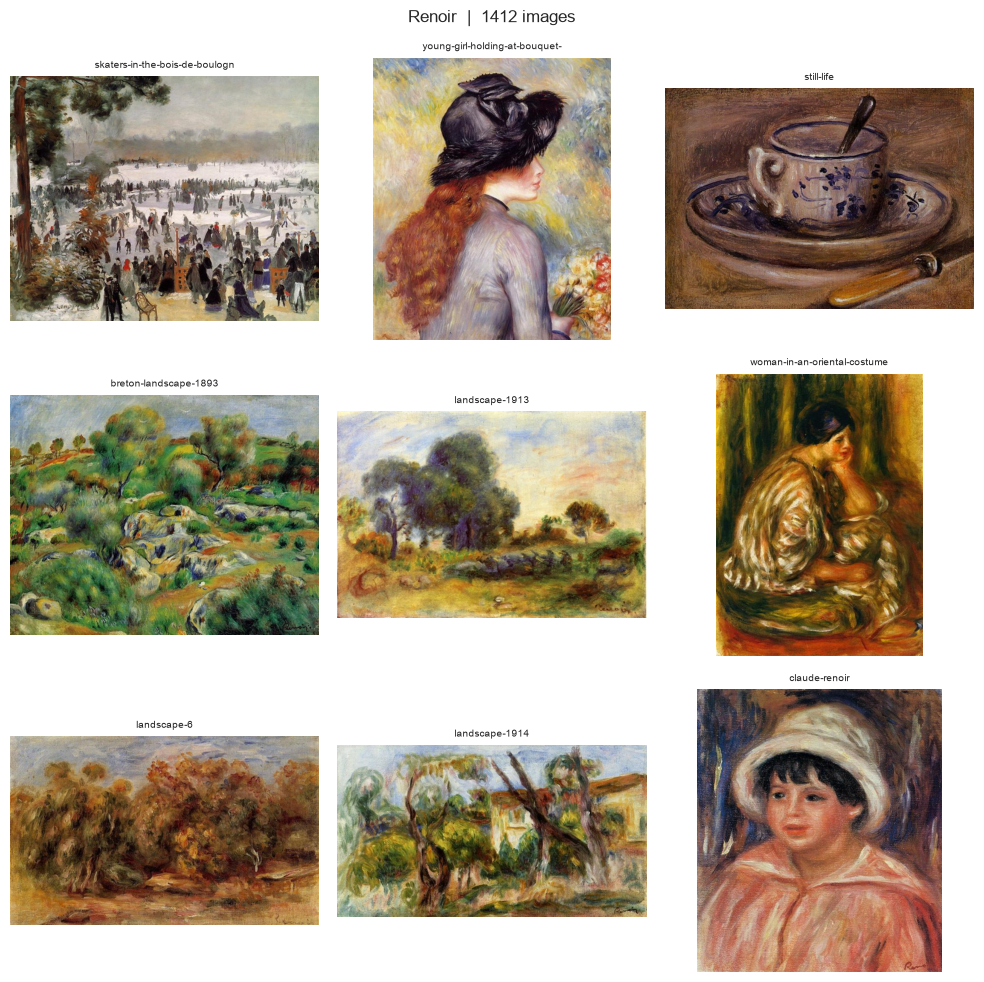

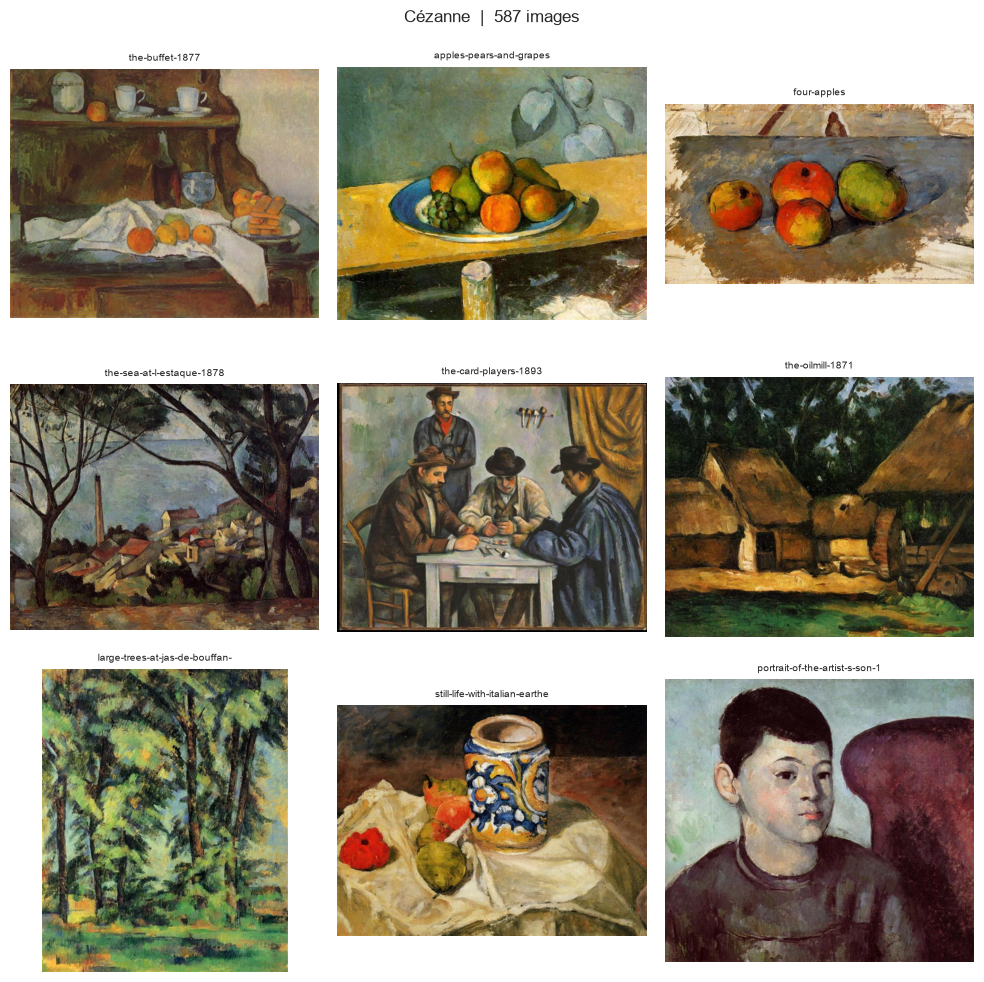

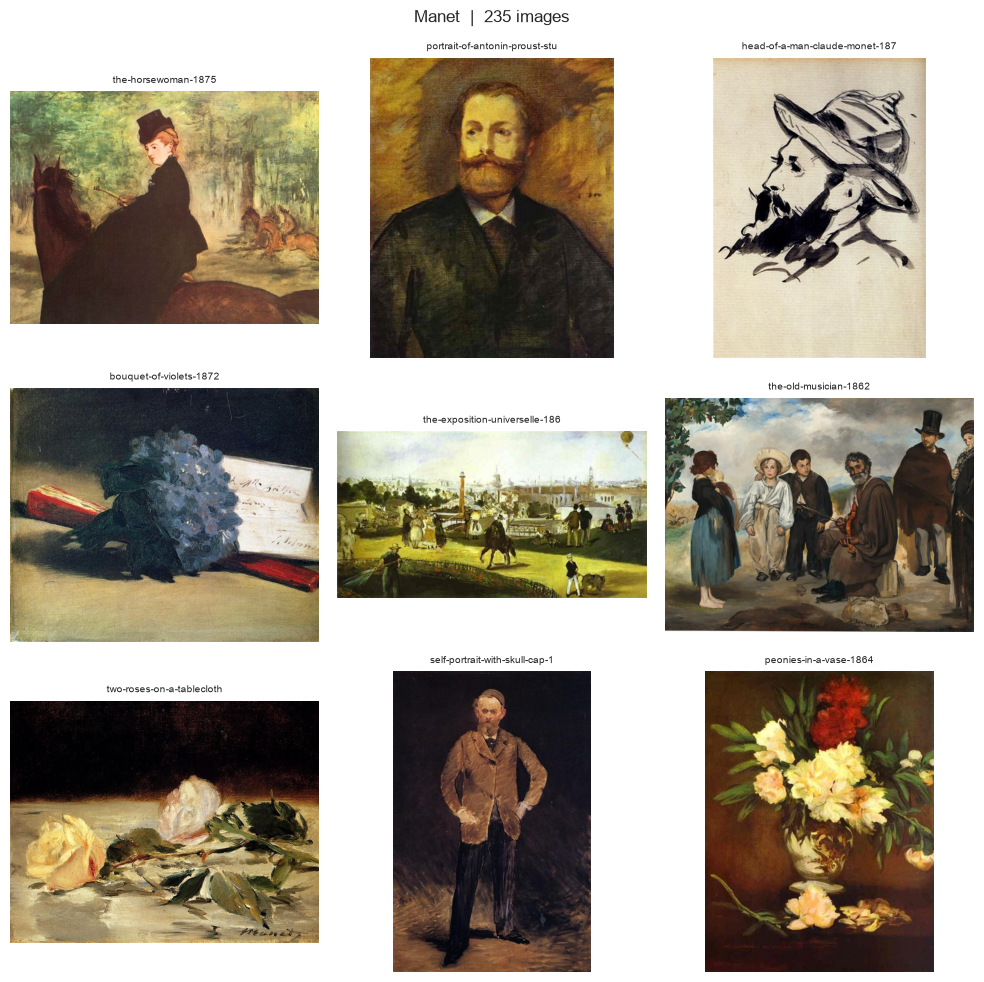

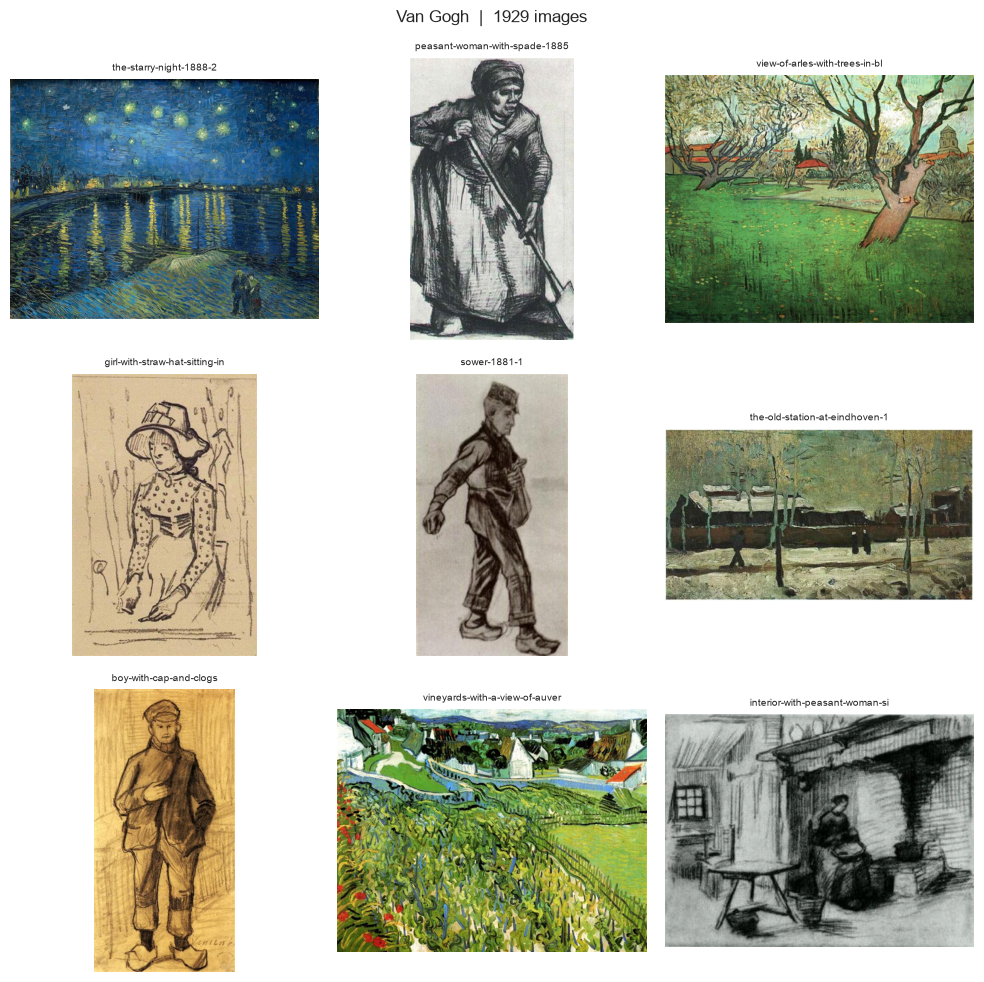

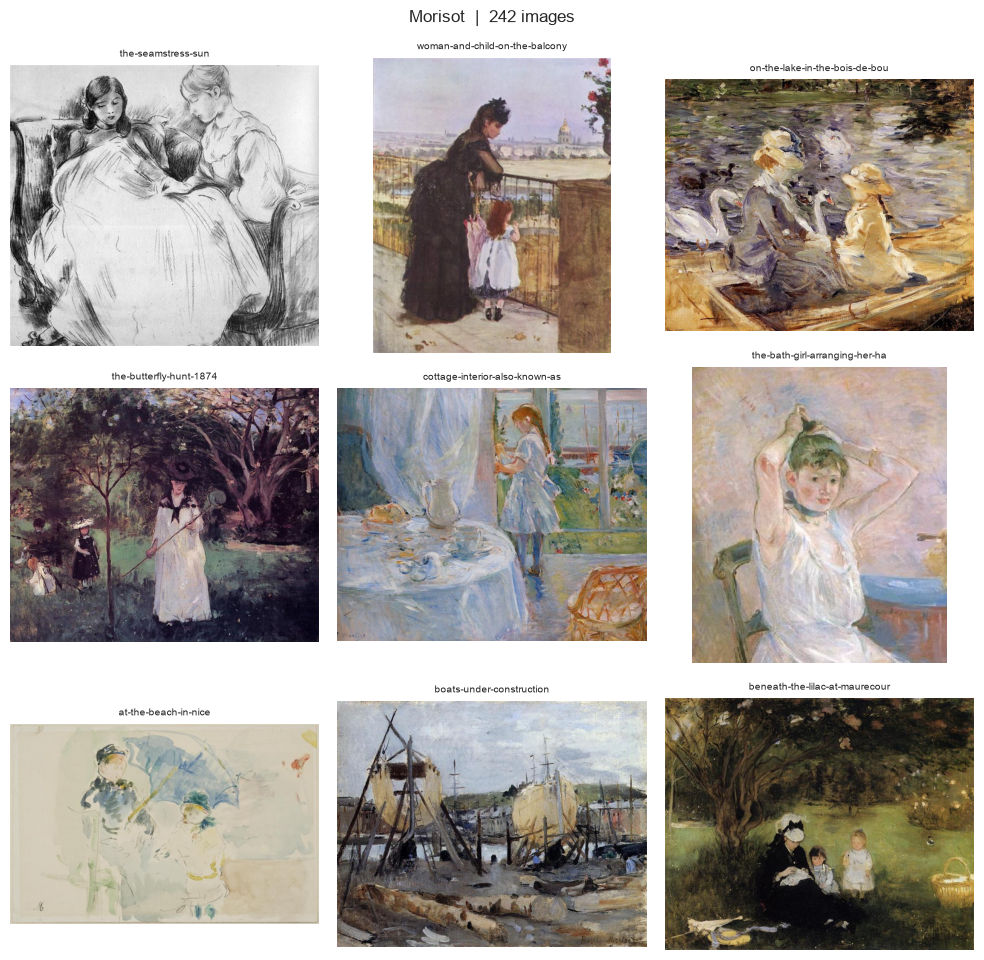

In [10]:
plot_artist_grids(df, artists=df['artist'].unique())

---
## 7. Remove duplicate images

PHash (perceptual hashing) deduplication converts each image into a short fingerprint based on its overall visual structure, typically by shrinking it, taking a frequency transform of the pixel values, and encoding the result as a compact binary code, so that visually similar images get similar codes even if they differ in file size, resolution, compression, or slight color changes. Two images are flagged as near-duplicates when the Hamming distance between their codes (the number of differing bits) falls below a chosen threshold. 

This matters for preventing data leakage because datasets like WikiArt often contain the same painting more than once, in different resolutions or crops, and artists themselves frequently painted the same scene multiple times as preparatory sketches, studies, or variations (Monet's haystacks and Rouen Cathedral series, Van Gogh's several versions of *Sunflowers*, Cézanne's many views of Mont Sainte-Victoire). If one copy or variation lands in the training set and another in the test set, the model is effectively tested on a scene it has already seen, so it can score well by recognizing the subject and composition instead of the painter's style. That inflates the evaluation scores and hides how poorly the model generalizes to truly new paintings. By detecting these near-duplicates beforehand, one can remove similar copies, so that the test results reflect real generalization instead of memorization.

In [12]:
# Deduplication cell: 
phash_encoder = PHash()
phash_dupes = phash_encoder.find_duplicates(
    image_dir=RAW,
    max_distance_threshold=9,
    recursive=True,
    num_enc_workers=1,
    num_dist_workers=1,
)
phash_dupes = {name: matches for name, matches in phash_dupes.items() if matches}
print(len(phash_dupes), "images with perceptual-hash matches")


2026-10-20 15:15:19,329: INFO Start: Calculating hashes...
100%|██████████| 5770/5770 [00:15<00:00, 363.23it/s]
2026-10-20 15:15:35,985: INFO End: Calculating hashes!
2026-10-20 15:15:35,986: INFO Start: Evaluating hamming distances for getting duplicates
2026-10-20 15:15:35,986: INFO Start: Retrieving duplicates using Cython Brute force algorithm
100%|██████████| 5770/5770 [00:15<00:00, 372.74it/s]
2026-10-20 15:15:51,934: INFO End: Retrieving duplicates using Cython Brute force algorithm
2026-10-20 15:15:51,934: INFO End: Evaluating hamming distances for getting duplicates


173 images with perceptual-hash matches


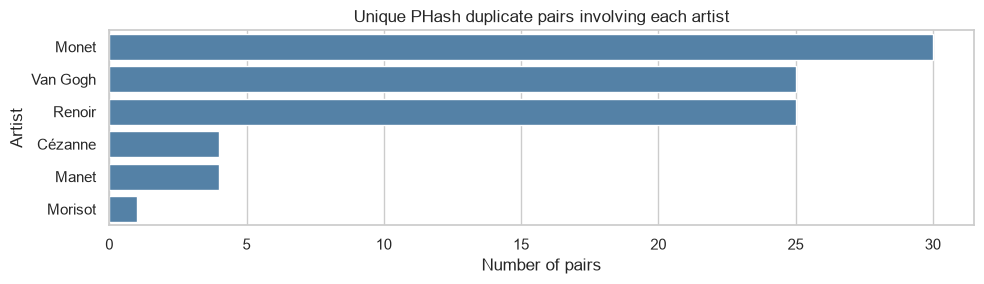

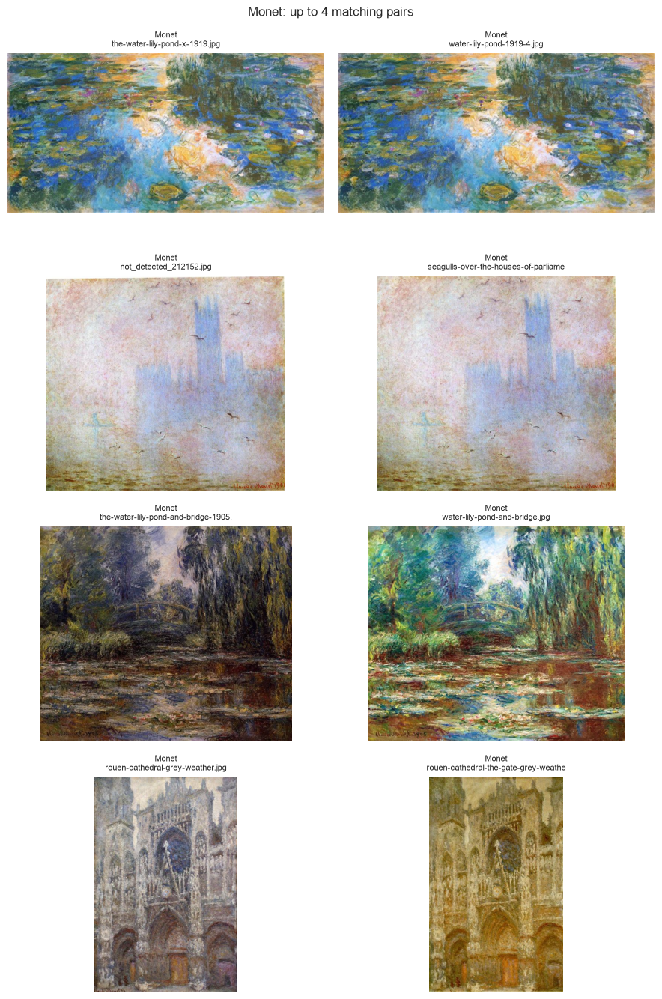

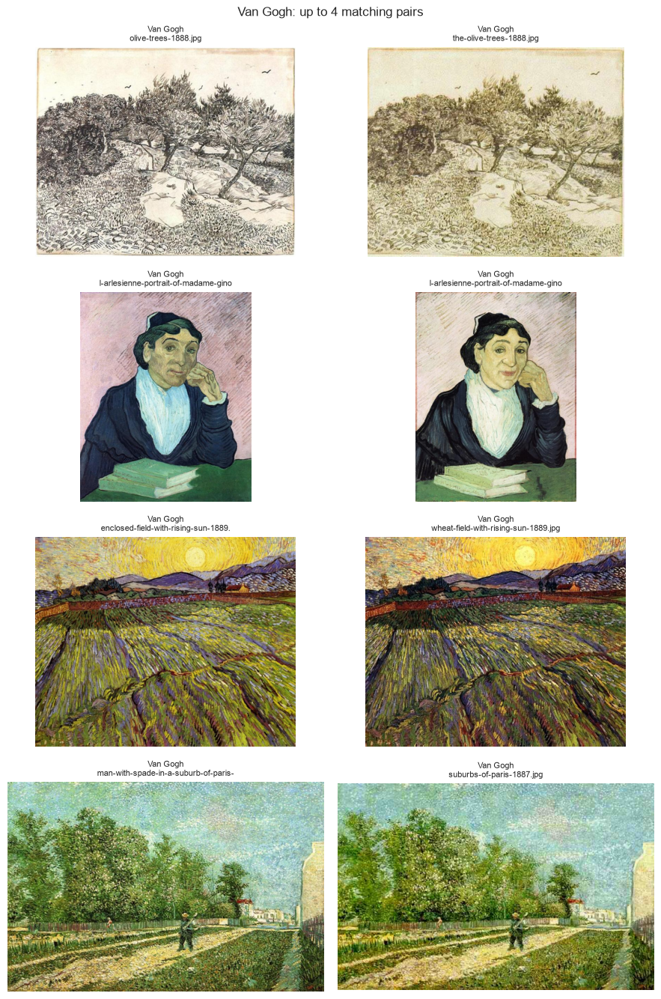

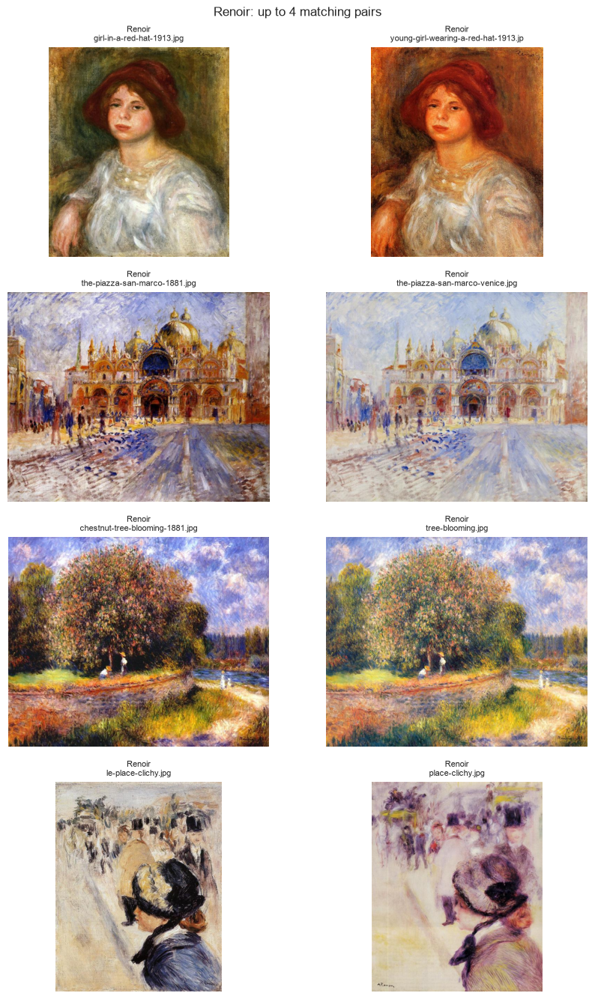

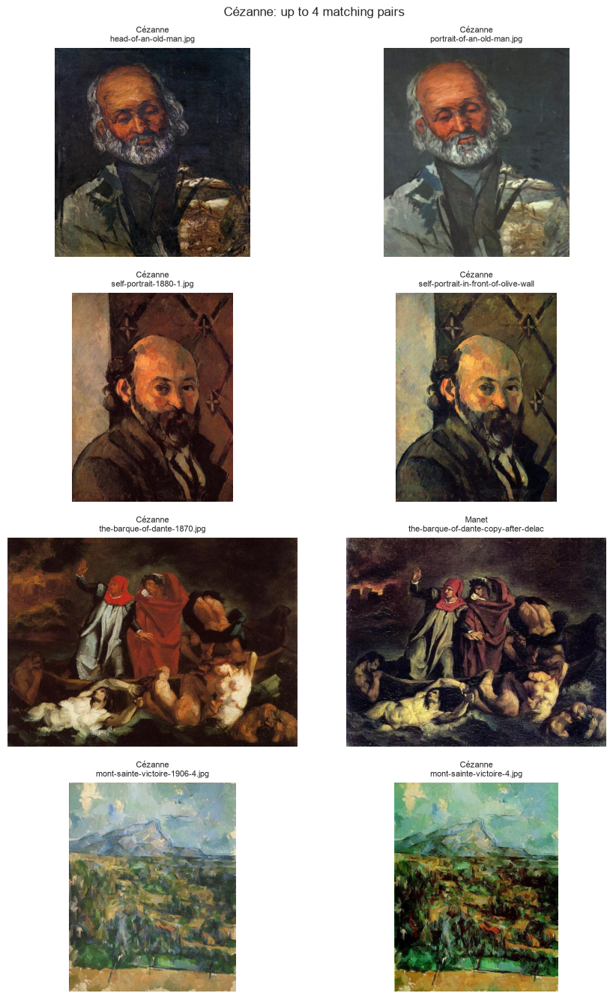

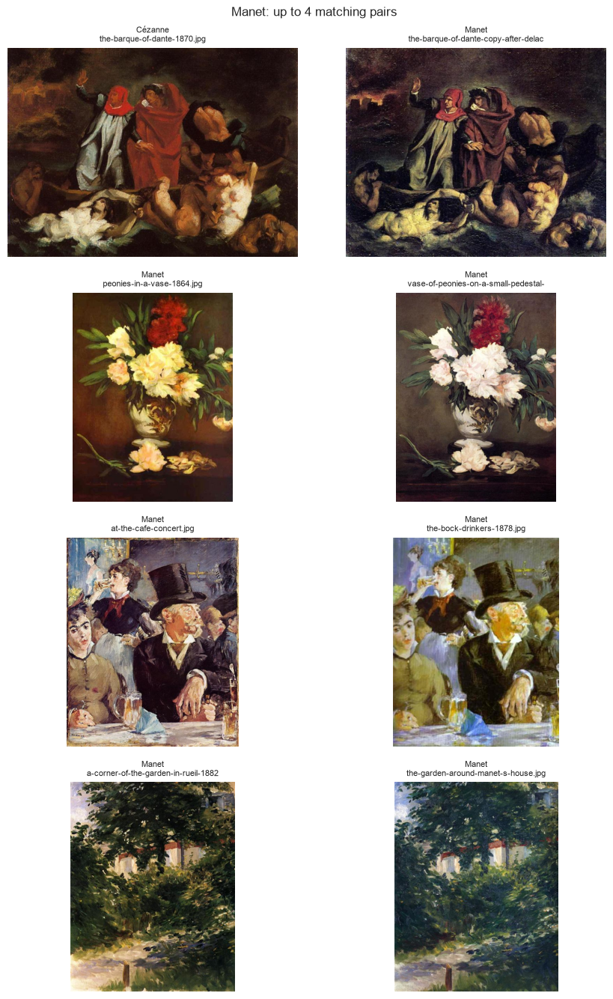

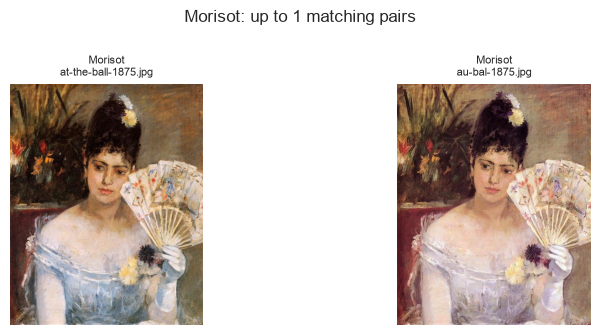

In [13]:
# Plot PHash matches by artist and inspect a few pairs.
phash_artist_counts = plot_phash_duplicates_by_artist(
    phash_dupes,
    df,
    root_dir=RAW,
    max_pairs_per_artist=4,
)


**Remove PHash duplicate paintings before splitting**

This collapses connected near-duplicate groups to one representative row before `data_split`. Removed rows remain available in `removed_phash_rows` for inspection.


In [14]:
# Always start from the complete image collection so rerunning this cell is stable.
df_all_paintings = add_image_sizes(build_dataframe(RAW))
dataset_names = {
    Path(path).resolve().relative_to(RAW.resolve()).as_posix()
    for path in df_all_paintings["path"]
}
matched_names = set(phash_dupes)
for matches in phash_dupes.values():
    matched_names.update(
        match[0] if isinstance(match, (tuple, list)) else str(match)
        for match in matches
    )
print(
    f"{len(phash_dupes)} files have PHash matches; "
    f"{len(matched_names & dataset_names)} matched files are in the full dataframe."
)
df, removed_phash_rows = remove_phash_duplicates(
    df_all_paintings,
    phash_dupes,
    root_dir=RAW,
)
print(f"Removed {len(removed_phash_rows)} duplicate rows; {len(df)} paintings remain.")
removed_phash_rows[["artist", "title", "path"]].head()


173 files have PHash matches; 173 matched files are in the full dataframe.
Removed 87 duplicate rows; 5683 paintings remain.


,artist,title,path
0,Monet,red-boats-argenteuil-1875-oil-on-canvas-1875,/Users/gabrielgomesdasilva/Library/Mobile Docu...
1,Monet,le-dejeuner-sur-lherbe-1866,/Users/gabrielgomesdasilva/Library/Mobile Docu...
2,Monet,water-lilies-40,/Users/gabrielgomesdasilva/Library/Mobile Docu...
3,Monet,the-rocks-of-belle-lle,/Users/gabrielgomesdasilva/Library/Mobile Docu...
4,Monet,the-pave-de-chailly-in-the-forest,/Users/gabrielgomesdasilva/Library/Mobile Docu...


---
## 8. Split once

The dataset is now split into training, validation, and test sets, each saved as a CSV file so that every following notebook uses exactly the same split.

In [15]:
train, val, test = data_split(df,  train_size=.7, val_size=.15, test_size=.15, output_dir= SPLIT)

train: 4059 rows (71.4%; requested 70.0%)
artist
Van Gogh    1361
Renoir       991
Monet        953
Cézanne     417
Morisot      171
Manet        166
Name: count, dtype: int64 

val: 812 rows (14.3%; requested 15.0%)
artist
Van Gogh    272
Renoir      198
Monet       191
Cézanne     83
Morisot      35
Manet        33
Name: count, dtype: int64 

test: 812 rows (14.3%; requested 15.0%)
artist
Van Gogh    272
Renoir      198
Monet       191
Cézanne     83
Morisot      35
Manet        33
Name: count, dtype: int64 

Saved train split to /Users/gabrielgomesdasilva/Library/Mobile Documents/com~apple~CloudDocs/Education/Ironhack/Week 6/project-2-ml/data/split/split_train.csv
Saved val split to /Users/gabrielgomesdasilva/Library/Mobile Documents/com~apple~CloudDocs/Education/Ironhack/Week 6/project-2-ml/data/split/split_val.csv
Saved test split to /Users/gabrielgomesdasilva/Library/Mobile Documents/com~apple~CloudDocs/Education/Ironhack/Week 6/project-2-ml/data/split/split_test.csv


---
## 9. Baseline

Before training any real model, I cross-validated a `DummyClassifier` on the training set to set a performance floor that every later model must beat. The dummy ignores the image entirely and always predicts the most frequent class (Van Gogh), so its scores show what can be achieved from the class distribution alone. The results are very stable across the folds, with an accuracy of 0.335 ± 0.001 and a macro-F1 of 0.084 ± 0.000. The accuracy matches Van Gogh's 33.4% share of the dataset, and the tiny variation between folds shows that the stratified splits preserve the class proportions. The gap between the two metrics is the important finding: a model with no knowledge of painting style gets a third of the predictions right, which sounds respectable, but its macro-F1 is only 0.084, because it scores perfectly on one class (about 0.5 F1 for Van Gogh) and zero on the other five. This confirms why macro-F1 is our main metric. Accuracy alone would make a trivial majority-class predictor look reasonable, while macro-F1 exposes it. From here on, a model is only useful if it clearly beats 0.335 accuracy and, more importantly, 0.084 macro-F1, and its gains should show up across all six painters, especially the small classes (Manet and Morisot), not only on the dominant ones.

In [16]:
# Keep the target out of X; StratifiedGroupKFold uses artist labels and groups paintings by title.
X_train = train.drop(columns="artist")
y_train = train["artist"]
groups_train = train["title"]

model_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dummy = DummyClassifier(strategy="most_frequent")

baseline_scores = cross_validate(
    dummy,
    X_train,
    y_train,
    groups=groups_train,
    cv=model_cv,
    scoring=["accuracy", "f1_macro"],
    return_train_score=False,
)
baseline_fold_accuracy = baseline_scores["test_accuracy"]
baseline_fold_f1 = baseline_scores["test_f1_macro"]
print("Fold accuracies:", np.round(baseline_fold_accuracy, 4))
print(f"Baseline accuracy: {baseline_fold_accuracy.mean():.4f} ± {baseline_fold_accuracy.std():.4f} (mean ± SD)")
print("Fold macro F1 scores:", np.round(baseline_fold_f1, 4))
print(f"Baseline macro F1: {baseline_fold_f1.mean():.4f} ± {baseline_fold_f1.std():.4f} (mean ± SD)")


Fold accuracies: [0.3362 0.335  0.335  0.3354 0.335 ]
Baseline accuracy: 0.3353 ± 0.0005 (mean ± SD)
Fold macro F1 scores: [0.0839 0.0836 0.0836 0.0837 0.0836]
Baseline macro F1: 0.0837 ± 0.0001 (mean ± SD)
